# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

### Implementación y resultados

En la celda de código siguiente carga Iris y genera la tabla y el gráfico solicitados.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Cargamos Iris
iris_data = load_iris(as_frame=True)
df = iris_data.frame

# X contiene las cuatro medidas; y contiene la clase de cada flor.
X = iris_data.data
y = iris_data.target
print("Dimensiones de X (características):", X.shape)
print("Dimensiones de y (clases):", y.shape)

# Tabla solicitada: cinco ejemplos del conjunto.
display(df.tail(5))


Dimensiones de X (características): (150, 4)
Dimensiones de y (clases): (150,)


sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
6.7,3.0,5.2,2.3,2
6.3,2.5,5.0,1.9,2
6.5,3.0,5.2,2.0,2
6.2,3.4,5.4,2.3,2
5.9,3.0,5.1,1.8,2


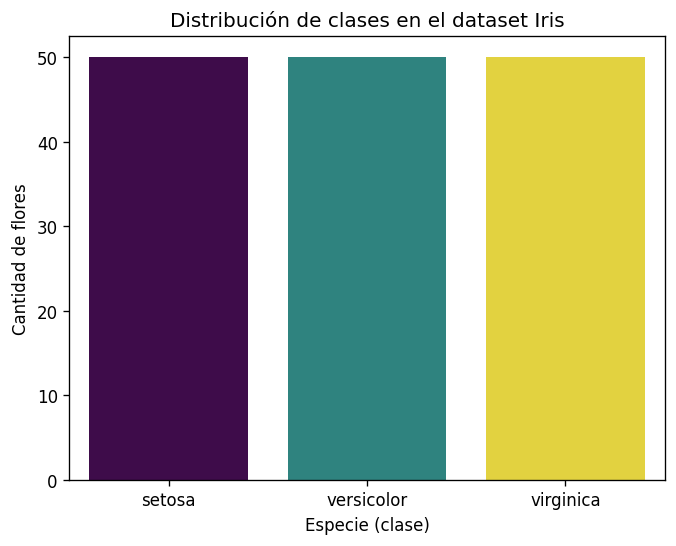

In [ ]:
# Cada barra cuenta cuántas flores pertenecen a una clase.
sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="viridis",
    legend=False,
)
plt.xticks(ticks=range(len(iris_data.target_names)), labels=iris_data.target_names)
plt.title("Distribución de clases en el dataset Iris")
plt.xlabel("Especie (clase)")
plt.ylabel("Cantidad de flores")
plt.show()


### Descripción del conjunto de datos

- **Qué representa cada instancia:** Cada fila representa una flor Iris individual.

- **Características y significado:** largo y ancho del sépalo, y largo y ancho del pétalo. Las cuatro medidas están expresadas en centímetros.

In [22]:
iris_data.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

- **Clases y cantidad de ejemplos:** `target` usa los códigos 0, 1 y 2 para representar, respectivamente, setosa, versicolor y virginica. 

- Hay 50 flores de cada especie, como muestra el gráfico.

- **Dimensiones de X e y:** `X` tiene forma `(150, 4)`: 150 flores y cuatro características. `y` tiene forma `(150,)`: una etiqueta de clase por flor.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
   - **Mi predicción:** Espero que la regresión logística, la SVM lineal y el MLP sean los más sensibles a la escala, porque sus pesos y su optimización dependen de la magnitud de las entradas. En cambio, los árboles y sus ensambles suelen depender del orden y de los umbrales de cada característica, así que espero que el escalamiento les afecte menos.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
   - **Mi predicción:** Apostaría por la regresión logística y la SVM lineal: ambas construyen fronteras lineales. Espero que un árbol profundo o un MLP puedan formar fronteras más detalladas, aunque eso no garantiza que clasifiquen mejor flores nuevas.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
   - **Mi predicción:** No puedo saberlo solo por el nombre del algoritmo. El resultado depende de cómo se separen las especies en estas medidas, de la complejidad elegida y de cuánto se ajuste cada modelo a los ejemplos de entrenamiento. La validación ayudará a elegir; la prueba dará una estimación final con datos que no se usaron para ajustar.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Implementación

La comparación usa las mismas particiones para todos los modelos. El escalador está dentro de cada pipeline para que aprenda medias y desviaciones solo al entrenar. Se elegirá la configuración con mejor F1 macro en validación, porque da el mismo peso a las tres especies; accuracy servirá como desempate. Después de fijarla, se volverá a entrenar con entrenamiento y validación juntos y se evaluará una sola vez en prueba.

### Preparación común

Primero separamos las 150 flores: 90 para entrenamiento, 30 para validación y 30 para prueba. `stratify` conserva la proporción de especies. Todos los modelos usarán estas mismas particiones.

Cada modelo tendrá su propio `Pipeline` con `StandardScaler`: al llamar a `fit`, el escalador aprende las medias y desviaciones con los datos de entrenamiento. Al predecir en validación, usa esas mismas medidas. Así evitamos que la transformación aprenda información de los conjuntos reservados.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

# Separamos antes de ajustar cualquier transformación y conservamos las proporciones de clase.
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42
)
X_validation, X_test, y_validation, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=42
)
print(
    f"Particiones: entrenamiento={len(y_train)}, "
    f"validación={len(y_validation)}, prueba={len(y_test)}"
)


# Guardaremos aquí la configuración elegida de cada clasificador.
best_validation = {}

def validation_metrics(prediction):
    return {
        "Accuracy": accuracy_score(y_validation, prediction),
        "F1 macro": f1_score(y_validation, prediction, average="macro"),
    }

Particiones: entrenamiento=90, validación=30, prueba=30


### Gaussian Naive Bayes

Este modelo estima una distribución gaussiana para cada característica dentro de cada especie. Supone que las características son independientes una vez conocida la clase. `var_smoothing` añade un pequeño suavizado a las varianzas para evitar problemas numéricos.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [24]:
nb_initial_params = {'var_smoothing': 1e-09}
nb_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", GaussianNB().set_params(**nb_initial_params)),
])
print("Configuración inicial:", nb_initial_params)

Configuración inicial: {'var_smoothing': 1e-09}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [25]:
nb_initial.fit(X_train, y_train)
nb_initial_prediction = nb_initial.predict(X_validation)
nb_initial_metrics = validation_metrics(nb_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Gaussian Naive Bayes',
    **nb_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Gaussian Naive Bayes,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Solo cambiaremos el suavizado; el resto del modelo se mantiene igual. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [26]:
nb_grid = {'var_smoothing': [1e-07, 1e-09, 1e-11]}
nb_candidates = []
for order, params in enumerate(ParameterGrid(nb_grid)):
    if params == nb_initial_params:
        candidate = nb_initial
        prediction = nb_initial_prediction
    else:
        candidate = clone(nb_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    nb_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in nb_candidates
]).round(3))

best_validation['Gaussian Naive Bayes'] = max(
    nb_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Gaussian Naive Bayes']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,{'var_smoothing': 1e-07},0.933,0.933
1,{'var_smoothing': 1e-09},0.933,0.933
2,{'var_smoothing': 1e-11},0.933,0.933


Configuración congelada: {'var_smoothing': 1e-07}


### Regresión logística

La regresión logística multiclase combina las cuatro medidas para estimar la probabilidad de cada especie. Sus fronteras de decisión son lineales. `C` controla la regularización: un valor menor limita más los pesos.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [27]:
logistic_initial_params = {'C': 1.0}
logistic_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000, random_state=42).set_params(**logistic_initial_params)),
])
print("Configuración inicial:", logistic_initial_params)

Configuración inicial: {'C': 1.0}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [28]:
logistic_initial.fit(X_train, y_train)
logistic_initial_prediction = logistic_initial.predict(X_validation)
logistic_initial_metrics = validation_metrics(logistic_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Regresión logística',
    **logistic_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Regresión logística,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Compararemos tres valores de `C` para ver cuánto conviene limitar los pesos. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [29]:
logistic_grid = {'C': [0.1, 1.0, 10.0]}
logistic_candidates = []
for order, params in enumerate(ParameterGrid(logistic_grid)):
    if params == logistic_initial_params:
        candidate = logistic_initial
        prediction = logistic_initial_prediction
    else:
        candidate = clone(logistic_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    logistic_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in logistic_candidates
]).round(3))

best_validation['Regresión logística'] = max(
    logistic_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Regresión logística']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,{'C': 0.1},0.867,0.865
1,{'C': 1.0},0.933,0.933
2,{'C': 10.0},0.933,0.933


Configuración congelada: {'C': 1.0}


### SVM lineal

La SVM lineal busca fronteras que separen las clases con margen. `C` controla cuánto penaliza los errores durante el entrenamiento: un valor mayor les da más importancia. Sus puntuaciones de decisión no son probabilidades.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [30]:
svm_initial_params = {'C': 1.0}
svm_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(max_iter=10000, random_state=42).set_params(**svm_initial_params)),
])
print("Configuración inicial:", svm_initial_params)

Configuración inicial: {'C': 1.0}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [31]:
svm_initial.fit(X_train, y_train)
svm_initial_prediction = svm_initial.predict(X_validation)
svm_initial_metrics = validation_metrics(svm_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'SVM lineal',
    **svm_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,SVM lineal,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Probaremos tres valores de `C`, usando las métricas de validación para elegir. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [32]:
svm_grid = {'C': [0.1, 1.0, 10.0]}
svm_candidates = []
for order, params in enumerate(ParameterGrid(svm_grid)):
    if params == svm_initial_params:
        candidate = svm_initial
        prediction = svm_initial_prediction
    else:
        candidate = clone(svm_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    svm_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in svm_candidates
]).round(3))

best_validation['SVM lineal'] = max(
    svm_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['SVM lineal']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,{'C': 0.1},0.833,0.829
1,{'C': 1.0},0.933,0.933
2,{'C': 10.0},0.933,0.933


Configuración congelada: {'C': 10.0}


### Árbol de decisión

El árbol clasifica mediante preguntas sobre las medidas, por ejemplo si el ancho del pétalo supera un umbral. `max_depth` limita cuántos niveles puede tener y `min_samples_leaf` exige un mínimo de flores en cada hoja. Un árbol muy profundo puede ajustarse demasiado al entrenamiento.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [33]:
tree_initial_params = {'max_depth': None, 'min_samples_leaf': 1}
tree_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(random_state=42).set_params(**tree_initial_params)),
])
print("Configuración inicial:", tree_initial_params)

Configuración inicial: {'max_depth': None, 'min_samples_leaf': 1}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [34]:
tree_initial.fit(X_train, y_train)
tree_initial_prediction = tree_initial.predict(X_validation)
tree_initial_metrics = validation_metrics(tree_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Árbol de decisión',
    **tree_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Árbol de decisión,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Compararemos árboles de distinta profundidad y dos tamaños mínimos de hoja. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [35]:
tree_grid = {'max_depth': [2, 3, None], 'min_samples_leaf': [3, 1]}
tree_candidates = []
for order, params in enumerate(ParameterGrid(tree_grid)):
    if params == tree_initial_params:
        candidate = tree_initial
        prediction = tree_initial_prediction
    else:
        candidate = clone(tree_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    tree_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in tree_candidates
]).round(3))

best_validation['Árbol de decisión'] = max(
    tree_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Árbol de decisión']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'max_depth': 2, 'min_samples_leaf': 3}",0.900,0.900
1,"{'max_depth': 2, 'min_samples_leaf': 1}",0.900,0.900
2,"{'max_depth': 3, 'min_samples_leaf': 3}",0.967,0.967
3,"{'max_depth': 3, 'min_samples_leaf': 1}",0.967,0.967
4,"{'max_depth': None, 'min_samples_leaf': 3}",0.967,0.967
5,"{'max_depth': None, 'min_samples_leaf': 1}",0.933,0.933


Configuración congelada: {'max_depth': 3, 'min_samples_leaf': 3}


### Random Forest

Random Forest combina las predicciones de varios árboles. Cada árbol usa una muestra aleatoria del entrenamiento y considera subconjuntos de características al dividir. Esta variedad ayuda a reducir la variación que tendría un solo árbol. `n_estimators` indica cuántos árboles se construyen.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [36]:
forest_initial_params = {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}
forest_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_jobs=-1, random_state=42).set_params(**forest_initial_params)),
])
print("Configuración inicial:", forest_initial_params)

Configuración inicial: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [37]:
forest_initial.fit(X_train, y_train)
forest_initial_prediction = forest_initial.predict(X_validation)
forest_initial_metrics = validation_metrics(forest_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Random Forest',
    **forest_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Random Forest,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Probaremos 100 o 200 árboles, junto con límites de profundidad y tamaño de hoja. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [38]:
forest_grid = {'n_estimators': [100, 200], 'max_depth': [3, 5, None], 'min_samples_leaf': [2, 1]}
forest_candidates = []
for order, params in enumerate(ParameterGrid(forest_grid)):
    if params == forest_initial_params:
        candidate = forest_initial
        prediction = forest_initial_prediction
    else:
        candidate = clone(forest_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    forest_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in forest_candidates
]).round(3))

best_validation['Random Forest'] = max(
    forest_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Random Forest']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'max_depth': 3, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
1,"{'max_depth': 3, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
2,"{'max_depth': 3, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
3,"{'max_depth': 3, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
4,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
5,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
6,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
7,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
8,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.933,0.933
9,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.933,0.933


Configuración congelada: {'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}


### Gradient Boosting

Gradient Boosting construye árboles en secuencia: cada nuevo árbol intenta mejorar lo que el conjunto todavía predice mal, siguiendo la función de pérdida. `learning_rate` controla el aporte de cada árbol, `n_estimators` la cantidad de etapas y `max_depth` la complejidad de cada árbol.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [39]:
boosting_initial_params = {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3}
boosting_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", GradientBoostingClassifier(random_state=42).set_params(**boosting_initial_params)),
])
print("Configuración inicial:", boosting_initial_params)

Configuración inicial: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [40]:
boosting_initial.fit(X_train, y_train)
boosting_initial_prediction = boosting_initial.predict(X_validation)
boosting_initial_metrics = validation_metrics(boosting_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Gradient Boosting',
    **boosting_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Gradient Boosting,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Compararemos dos cantidades de árboles, dos tasas de aprendizaje y tres profundidades pequeñas. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [41]:
boosting_grid = {'n_estimators': [50, 100], 'learning_rate': [0.05, 0.1], 'max_depth': [1, 2, 3]}
boosting_candidates = []
for order, params in enumerate(ParameterGrid(boosting_grid)):
    if params == boosting_initial_params:
        candidate = boosting_initial
        prediction = boosting_initial_prediction
    else:
        candidate = clone(boosting_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    boosting_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in boosting_candidates
]).round(3))

best_validation['Gradient Boosting'] = max(
    boosting_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Gradient Boosting']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'learning_rate': 0.05, 'max_depth': 1, 'n_est...",0.967,0.967
1,"{'learning_rate': 0.05, 'max_depth': 1, 'n_est...",0.933,0.933
2,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.967,0.967
3,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.967,0.967
4,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.967,0.967
5,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.933,0.933
6,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.933,0.933
7,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.933,0.933
8,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.967,0.967
9,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.933,0.933


Configuración congelada: {'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 50}


### MLP

El MLP tiene una capa oculta que transforma las medidas mediante una activación no lineal. Esto le permite formar fronteras más complejas que un modelo lineal. `hidden_layer_sizes` define las neuronas de esa capa y `alpha` controla la regularización de los pesos. Con `early_stopping`, reserva internamente una parte del entrenamiento para decidir cuándo detenerse; no usa nuestra partición externa de validación para entrenar.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [42]:
mlp_initial_params = {'hidden_layer_sizes': (16,), 'alpha': 0.0001}
mlp_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(solver="adam", max_iter=2000, early_stopping=True,
        n_iter_no_change=30, random_state=42).set_params(**mlp_initial_params)),
])
print("Configuración inicial:", mlp_initial_params)

Configuración inicial: {'hidden_layer_sizes': (16,), 'alpha': 0.0001}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [43]:
mlp_initial.fit(X_train, y_train)
mlp_initial_prediction = mlp_initial.predict(X_validation)
mlp_initial_metrics = validation_metrics(mlp_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'MLP',
    **mlp_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,MLP,0.733,0.707


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Mantendremos una sola capa oculta y compararemos tres tamaños y dos niveles de regularización. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [44]:
mlp_grid = {'hidden_layer_sizes': [(8,), (16,), (32,)], 'alpha': [0.01, 0.0001]}
mlp_candidates = []
for order, params in enumerate(ParameterGrid(mlp_grid)):
    if params == mlp_initial_params:
        candidate = mlp_initial
        prediction = mlp_initial_prediction
    else:
        candidate = clone(mlp_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    mlp_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in mlp_candidates
]).round(3))

best_validation['MLP'] = max(
    mlp_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['MLP']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'alpha': 0.01, 'hidden_layer_sizes': (8,)}",0.300,0.222
1,"{'alpha': 0.01, 'hidden_layer_sizes': (16,)}",0.733,0.707
2,"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}",0.700,0.651
3,"{'alpha': 0.0001, 'hidden_layer_sizes': (8,)}",0.300,0.222
4,"{'alpha': 0.0001, 'hidden_layer_sizes': (16,)}",0.733,0.707
5,"{'alpha': 0.0001, 'hidden_layer_sizes': (32,)}",0.700,0.651


Configuración congelada: {'alpha': 0.01, 'hidden_layer_sizes': (16,)}


## Resultados

### Paso 6. Evaluación final en prueba

Ya elegimos las siete configuraciones usando validación. Ahora volvemos a entrenar cada una con las 120 flores de entrenamiento y validación juntas. El escalador también se vuelve a ajustar con esas 120 flores. Las 30 de prueba siguen separadas y solo se usan para la evaluación final.

La tabla reúne modelo, transformación, hiperparámetros, accuracy de prueba y F1 macro de prueba, como pide el profesor. Estos resultados no se usan para cambiar otra vez los hiperparámetros.

In [45]:
# Las configuraciones quedan congeladas. Reentrenamos con entrenamiento + validación;
# la prueba sigue separada y no participa en la selección.
X_development = pd.concat([X_train, X_validation])
y_development = pd.concat([y_train, y_validation])
final_models = {}
predictions_test = {}
for model_name, selected in best_validation.items():
    final_model = clone(selected["pipeline"])
    final_model.fit(X_development, y_development)
    final_models[model_name] = final_model
    predictions_test[model_name] = final_model.predict(X_test)

# Tabla final: se informa la prueba, pero no se vuelve a ajustar con ella.
def format_params(model_name, params):
    reported = dict(params)
    if model_name == "MLP":
        reported.update({"solver": "adam", "early_stopping": True})
    return ", ".join(f"{name}={value}" for name, value in reported.items())

test_rows = []
for model_name, selected in best_validation.items():
    prediction = predictions_test[model_name]
    test_rows.append({
        "Modelo": model_name,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": format_params(model_name, selected["Parámetros"]),
        "Accuracy de prueba": accuracy_score(y_test, prediction),
        "F1 macro de prueba": f1_score(y_test, prediction, average="macro"),
    })
results_test = pd.DataFrame(test_rows)
print("Resultados finales en el conjunto de prueba:")
display(results_test.round({"Accuracy de prueba": 3, "F1 macro de prueba": 3}))

Resultados finales en el conjunto de prueba:


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,var_smoothing=1e-07,0.933,0.933
1,Regresión logística,StandardScaler,C=1.0,0.933,0.933
2,SVM lineal,StandardScaler,C=10.0,0.933,0.933
3,Árbol de decisión,StandardScaler,"max_depth=3, min_samples_leaf=3",0.933,0.933
4,Random Forest,StandardScaler,"max_depth=3, min_samples_leaf=2, n_estimators=100",0.933,0.933
5,Gradient Boosting,StandardScaler,"learning_rate=0.05, max_depth=1, n_estimators=50",0.933,0.933
6,MLP,StandardScaler,"alpha=0.01, hidden_layer_sizes=(16,), solver=a...",0.867,0.861


### Matrices de confusión

Las filas indican la especie real y las columnas la predicha. Los valores de la diagonal son aciertos; los que quedan fuera son confusiones entre especies. Usamos el mismo orden de clases y las mismas flores de prueba para Naive Bayes, SVM y MLP.

#### Gaussian Naive Bayes

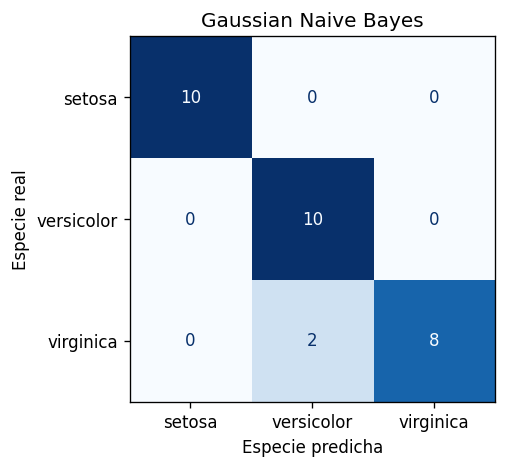

In [ ]:
fig, axis = plt.subplots(figsize=(5, 4))
matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test['Gaussian Naive Bayes'],
    labels=np.arange(len(iris_data.target_names)),
    display_labels=iris_data.target_names,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_title('Gaussian Naive Bayes')
axis.set_xlabel("Especie predicha")
axis.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

#### SVM lineal

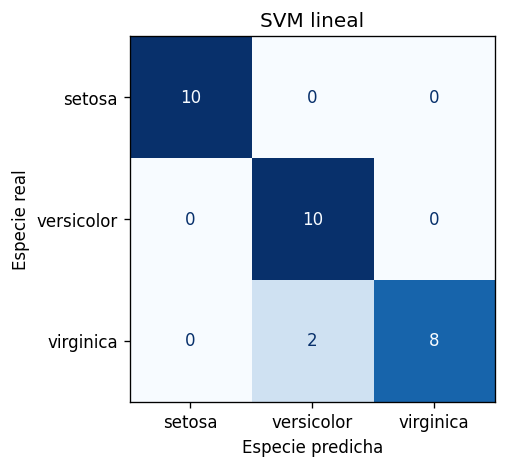

In [ ]:
fig, axis = plt.subplots(figsize=(5, 4))
matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test['SVM lineal'],
    labels=np.arange(len(iris_data.target_names)),
    display_labels=iris_data.target_names,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_title('SVM lineal')
axis.set_xlabel("Especie predicha")
axis.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

#### MLP

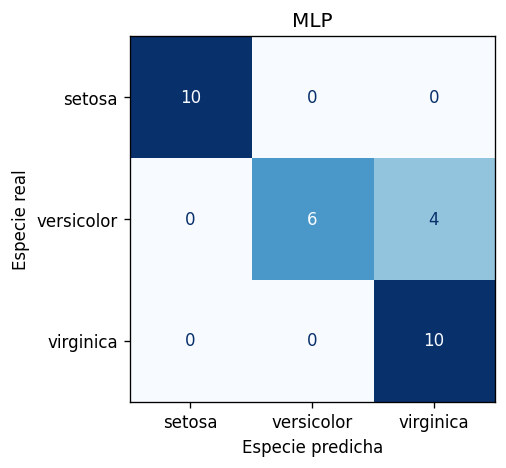

In [ ]:
fig, axis = plt.subplots(figsize=(5, 4))
matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test['MLP'],
    labels=np.arange(len(iris_data.target_names)),
    display_labels=iris_data.target_names,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_title('MLP')
axis.set_xlabel("Especie predicha")
axis.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

### Dos ejemplos mal clasificados

Buscamos dos flores distintas cuya predicción no coincida con su especie real. Mostramos sus cuatro medidas para poder discutir la confusión. Si no hubiera suficientes errores en prueba, completaríamos los ejemplos con validación, indicando de qué partición viene cada uno.

In [ ]:
# Elegimos dos errores reales de prueba de modelos distintos si hace falta.
# Si en prueba no hubiera dos casos distintos, completamos con errores de validación.
error_examples = []
for partition_name, features, actual, predictions_by_model in [
    ("prueba", X_test, np.asarray(y_test), predictions_test),
    (
        "validación",
        X_validation,
        np.asarray(y_validation),
        {name: row["predicción_validación"] for name, row in best_validation.items()},
    ),
]:
    seen_indices = {row["Índice de flor"] for row in error_examples}
    for model_name in best_validation:
        prediction = np.asarray(predictions_by_model[model_name])
        for position in np.flatnonzero(prediction != actual):
            flower_index = int(features.index[position])
            if flower_index in seen_indices:
                continue
            feature_values = features.iloc[position]
            error_examples.append({
                "Partición": partition_name,
                "Modelo": model_name,
                "Índice de flor": flower_index,
                "Especie real": iris_data.target_names[int(actual[position])],
                "Especie predicha": iris_data.target_names[int(prediction[position])],
                **{column: feature_values[column] for column in X.columns},
            })
            seen_indices.add(flower_index)
            if len(error_examples) == 2:
                break
        if len(error_examples) == 2:
            break
    if len(error_examples) == 2:
        break

print("Dos ejemplos de errores para revisar (primero se buscan en prueba):")
if error_examples:
    display(pd.DataFrame(error_examples).round(2))
else:
    print("No aparecieron errores en prueba ni validación; no hay casos mal clasificados que describir.")

Dos ejemplos de errores para revisar (primero se buscan en prueba):


Partición,Modelo,Índice de flor,Especie real,Especie predicha,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
prueba,Gaussian Naive Bayes,134,virginica,versicolor,6.1,2.6,5.6,1.4
prueba,Gaussian Naive Bayes,133,virginica,versicolor,6.3,2.8,5.1,1.5


## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
   - En validación, el árbol y Gradient Boosting llegaron a 0.967. En la prueba, seis modelos empataron: Naive Bayes, regresión logística, SVM lineal, árbol, Random Forest y Gradient Boosting obtuvieron 0.933 en accuracy y F1 macro (28 aciertos de 30). No hay un ganador único en esta partición. El MLP obtuvo 0.867 de accuracy y 0.861 de F1 macro.

2. ¿Cuál fue el modelo más sencillo de programar?
   - Para mí, Gaussian Naive Bayes fue el más sencillo de configurar: estima cómo se distribuyen las características en cada clase y solo ajusté su nivel de suavizado (`var_smoothing`). El código de comparación comparte los mismos pasos para todos, así que esta sencillez se refiere a la configuración del modelo. Que sea sencillo no significa que tenga que ganar.

3. ¿Accuracy y F1 macro cuentan la misma historia?
   - Aquí cuentan una historia parecida: los seis modelos empatados tienen ambas métricas en 0.933; el MLP queda algo más abajo en las dos. No son la misma medida: accuracy resume cuántas predicciones fueron correctas, mientras que F1 macro calcula un F1 para cada especie y luego los promedia. En la matriz del MLP, por ejemplo, cuatro versicolor se confundieron con virginica; F1 macro ayuda a ver el desempeño por clase. Como la partición de prueba tiene diez flores de cada especie, ninguna clase domina el conteo total.

4. ¿Cuál es la diferencia entre las métricas macro y micro?
   - Macro calcula la métrica por separado para cada clase y luego promedia, dando el mismo peso a setosa, versicolor y virginica. Micro suma primero los aciertos y errores de todas las clases y calcula una métrica global. En una clasificación multiclase de una sola etiqueta como esta, F1 micro coincide con accuracy. En este experimento el conjunto está balanceado, así que no hay una especie con muchas más muestras que arrastre el promedio.

5. ¿Qué aporta el MLP frente a un modelo lineal?
   - La capa oculta del MLP puede transformar las medidas y, con una activación no lineal, representar fronteras más curvas que una regresión logística o una SVM lineal. Pero esa capacidad extra no se convirtió en mejor resultado aquí: el MLP quedó por debajo de los modelos lineales en la prueba y confundió cuatro versicolor con virginica. En esta partición, su mayor complejidad no trajo una ventaja medible; con un solo reparto no concluiría que siempre será peor.

**Análisis de errores:** Los dos ejemplos impresos son errores de Gaussian Naive Bayes: eran virginica y el modelo los predijo como versicolor. Tienen ancho de pétalo de 1.4 y 1.5 cm, respectivamente, una medida que ayuda a entender por qué el modelo pudo acercarlos a esa clase. Es una explicación compatible con esos ejemplos, no una causa demostrada: el modelo combina las cuatro medidas y Naive Bayes además supone independencia condicional entre características. Dos errores no bastan para afirmar que una medida concreta provocó la confusión.

**Alcance de la comparación:** Todos los modelos recibieron características estandarizadas, como pide la práctica. Por eso este experimento no mide qué habría pasado sin escalamiento y no permite atribuir las diferencias de rendimiento a esa transformación. La prueba tiene solo 30 flores; un acierto cambia accuracy en unos 3.3 puntos porcentuales. Las diapositivas de clase recuerdan que validación sirve para elegir y prueba para estimar el resultado final, no para abrir otra ronda de ajustes.


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

**Mi predicción:** [Escribe aquí tu respuesta y justificación antes de entrenar los modelos.]

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

## Resultados

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Implementación y resultados

En la celda de código siguiente implementa los modelos y genera la tabla, los gráficos y los ejemplos de errores solicitados. Incluye también la comparación de coeficientes y errores de entrenamiento y validación para Ridge y Lasso.


In [ ]:
# TODO: implementa la comparación de regresores y genera las métricas, gráficos y análisis solicitados.


## Interpretación

Aquí explica qué significan los resultados usando conceptos de Machine Learning. Relaciona tus observaciones con la capacidad del modelo y su generalización, el efecto de la regularización, qué penaliza cada métrica y los límites de interpretar predicción como causalidad. Apóyate en la tabla, los gráficos y los ejemplos que obtuviste.

1. ¿Qué modelo tuvo el mejor desempeño?
   - **Respuesta:** [Compara las métricas y justifica tu conclusión.]

2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
   - **Respuesta:** [Explica qué tipo de error destaca cada métrica y relaciónalo con los resultados.]

3. ¿Cómo se interpreta un R² negativo?
   - **Respuesta:** [Explica su significado en el contexto de la evaluación realizada.]

4. ¿Qué efecto tuvo aumentar la regularización?
   - **Respuesta:** [Describe lo que observaste al aumentar la penalización.]

5. ¿Qué puede explicar los errores grandes?
   - **Respuesta:** [Usa los ejemplos y gráficos para proponer explicaciones prudentes.]

6. ¿Un coeficiente predictivo demuestra una relación causal?
   - **Respuesta:** [Explica qué permite concluir un modelo predictivo y qué no demuestra por sí solo.]

**Análisis de regularización:** [Relaciona los cambios observados en coeficientes y errores de entrenamiento y validación con la complejidad del modelo y su generalización.]
